# DSCI 552 Midterm Exam 1

**Name:** Manvika Satish  
**GitHub Username:** manvsatish  
**USC ID:** 5582061880

## Midterm Problem #8

## (a) Data Exploration and Preprocessing

### (i) Import and Inspect the Dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#random seed
RANDOM_STATE = 552

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [2]:
# dataset path relative to the notebook dir
data_path = Path("../data/student-mat.csv")
print("Dataset exists:", data_path.exists())
print("Dataset path:", data_path)

# stop if dataset is not in expected location
assert data_path.exists(), (
    f"Dataset was not found at {data_path}"
)

# uci student-performance csv uses semicolons to separate
student_data = pd.read_csv(data_path, sep=";",)
print("Dataset shape:", student_data.shape)
display(student_data.head()) #first five observations
print("\nDataset information:")
student_data.info()
print("\nMissing values by column:")
display(student_data.isna().sum())
print("\nNumeric summary:")
display(student_data.describe().T)

Dataset exists: True
Dataset path: ../data/student-mat.csv
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-n

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


### (ii) Select and Preprocess the Required Variables

I selected the variables specified in the question, encoded `schoolsup` as 0 for `no` and 1 for `yes`, and combined weekday and weekend alcohol consumption into `alc` by taking their average. The original `Dalc` and `Walc` columns are then removed.

In [3]:
#required variables
selected_columns = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]
preprocessed_data = student_data[selected_columns].copy()

#encode extra educational support as a binary num var
preprocessed_data["schoolsup"] = (preprocessed_data["schoolsup"].map({"no": 0, "yes": 1}))
preprocessed_data["alc"] = (preprocessed_data[["Dalc", "Walc"]].mean(axis=1)) # weekday + weekend alc consumption
preprocessed_data = preprocessed_data.drop(columns=["Dalc", "Walc"]) # remove the two original alcohol-consumption vars

# final col order
preprocessed_data = preprocessed_data[["age", "studytime", "schoolsup", "goout", "health", "absences", "alc", "G3"]]

# validate results
assert preprocessed_data["schoolsup"].isin([0, 1]).all()
assert not preprocessed_data.isna().any().any()
assert preprocessed_data.shape == (395, 8)

print("Preprocessed dataset shape:", preprocessed_data.shape,)
print("\nPreprocessed data types:")
display(preprocessed_data.dtypes.to_frame(name="Data Type"))
print("\nFirst five preprocessed rows:")
display(preprocessed_data.head())
print("\nPreprocessed summary:")
display(preprocessed_data.describe().T)

Preprocessed dataset shape: (395, 8)

Preprocessed data types:


,Data Type
age,int64
studytime,int64
schoolsup,int64
goout,int64
health,int64
absences,int64
alc,float64
G3,int64



First five preprocessed rows:


,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10



Preprocessed summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
schoolsup,395.0,0.129114,0.335751,0.0,0.0,0.0,0.0,1.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
health,395.0,3.554430,1.390303,1.0,3.0,4.0,5.0,5.0
absences,395.0,5.708861,8.003096,0.0,0.0,4.0,8.0,75.0
alc,395.0,1.886076,0.992195,1.0,1.0,1.5,2.5,5.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


### (iii) Outlier Detection Using the IQR Method

For each independent variable, I defined an outlier as an observation below $Q_1-1.5(IQR)$ or above $Q_3+1.5(IQR)$, where $IQR=Q_3-Q_1$. I reported the number of outliers and displayed boxplots for visual inspection. I didn't automatically remove these observations because the question only asked for their identification.

IQR outlier summary:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,16.0,18.0,2.0,13.00,21.00,1
1,studytime,1.0,2.0,1.0,-0.50,3.50,27
2,schoolsup,0.0,0.0,0.0,0.00,0.00,51
3,goout,2.0,4.0,2.0,-1.00,7.00,0
4,health,3.0,5.0,2.0,0.00,8.00,0
5,absences,0.0,8.0,8.0,-12.00,20.00,15
6,alc,1.0,2.5,1.5,-1.25,4.75,9


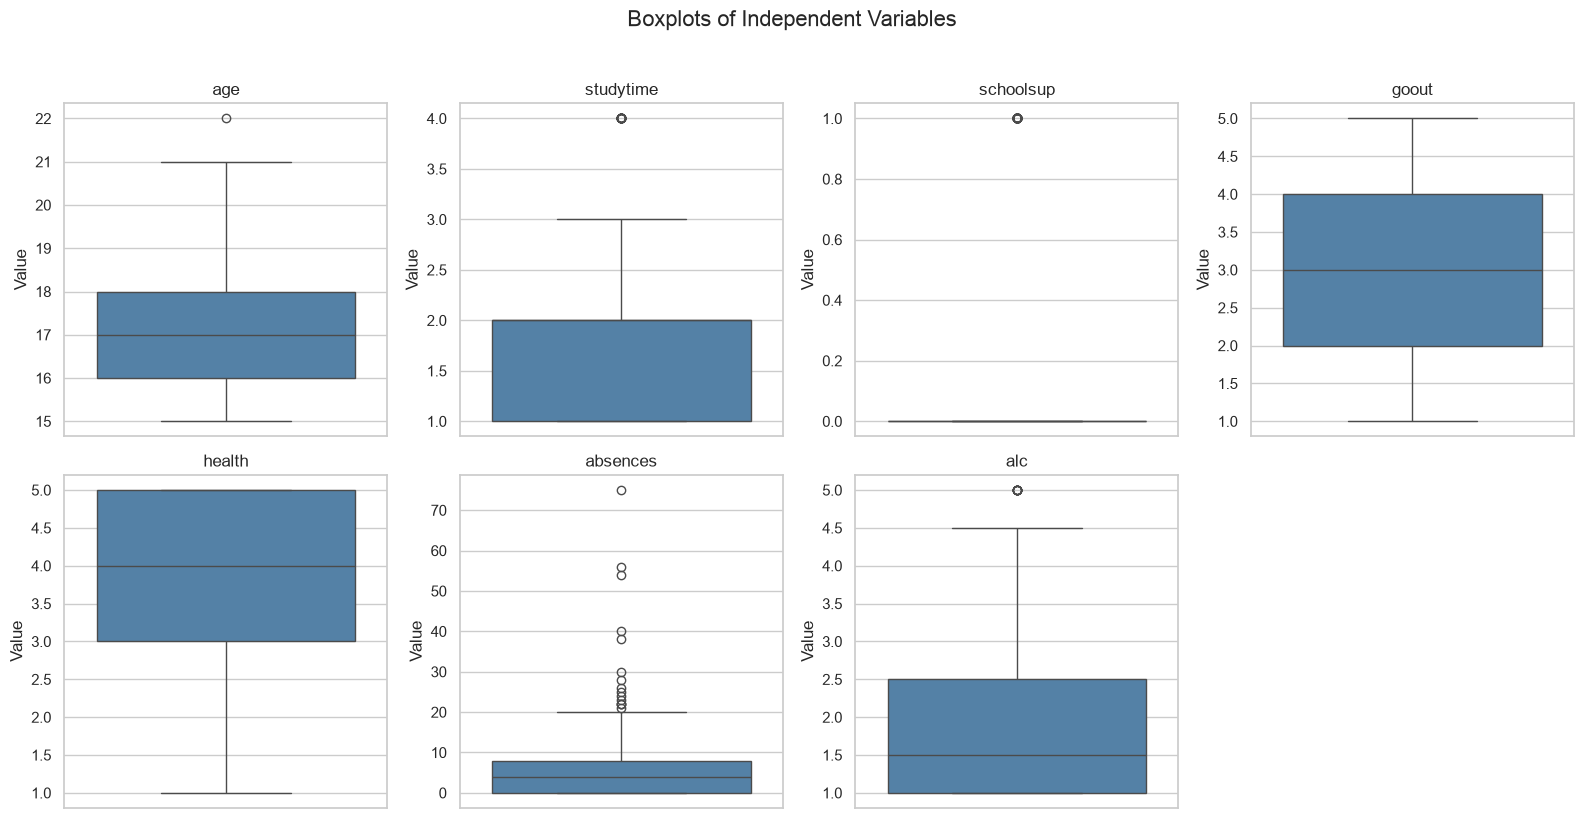

In [4]:
# sep the ind vars from the G3 target
feature_names = [column for column in preprocessed_data.columns if column != "G3"]
X = preprocessed_data[feature_names].copy()
y = preprocessed_data["G3"].copy()

# calculate iqr bounds and outlier counts for each predictor
outlier_rows = []

for feature_name in feature_names:
    first_quartile = X[feature_name].quantile(0.25)
    third_quartile = X[feature_name].quantile(0.75)
    interquartile_range = (third_quartile - first_quartile)

    lower_bound = (first_quartile - 1.5 * interquartile_range)
    upper_bound = (third_quartile + 1.5 * interquartile_range)

    outlier_mask = ((X[feature_name] < lower_bound) | (X[feature_name] > upper_bound))
    outlier_rows.append(
        {
            "Feature": feature_name,
            "Q1": first_quartile,
            "Q3": third_quartile,
            "IQR": interquartile_range,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": int(
                outlier_mask.sum()
            ),
        }
    )

outlier_summary = pd.DataFrame(outlier_rows)
print("IQR outlier summary:")
display(outlier_summary.round(3))

# one boxplot for every ind var
figure, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for axis, feature_name in zip(axes, feature_names):
    sns.boxplot(y=X[feature_name], ax=axis, color="steelblue")
    axis.set_title(feature_name)
    axis.set_ylabel("Value")

#hide unused 8th
for unused_axis in axes[len(feature_names):]:
    unused_axis.set_visible(False)

figure.suptitle("Boxplots of Independent Variables", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

The IQR method identified the largest number of apparent outliers in `schoolsup`, `studytime`, and `absences`. `schoolsup` is binary, and because both its first and third quartiles are zero, its IQR is zero. As a result, all 51 valid observations with `schoolsup=1` are  labeled as outliers. These are valid category values rather than erroneous data. Similarly, `studytime` and `alc` are bounded ordinal variables, so their flagged values represent valid high response levels. The `absences` variable contains 15 observations above 20 and is strongly right-skewed, making those observations more meaningful numerical outliers. Because the question asks only to identify the outliers, I kept all observations for the subsequent analysis.

### (iv) Standardization and Principal Component Analysis

I standardized the seven independent variables so that each has mean 0 and a standard deviation of 1. I then performed PCA and visualized the first two principal components, coloring each observation by its final grade, `G3`. I inspected the component loadings to determine which features contributed most strongly to PC1 and PC2.